<a href="https://colab.research.google.com/github/SitiMutmainah15/PCVK_GENAP_2026/blob/main/Week9_PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

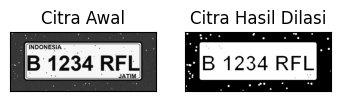

In [21]:
# Dilasi tanpa library
def dilasi_citra(F,w):
    # Size image
    p,q = F.shape

    imgD = np.zeros((p,q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w,w), dtype=np.uint8)
    constant1 = (w-1)//2

    # Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp*SED
            imgD[i,j] = np.max(product)

    return imgD

# Membaca citra
img_d = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


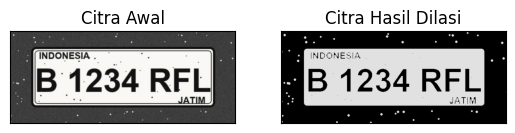

In [22]:
# Dilasi menggunakan library OpenCV

img = cv2.imread('/content/PLAT_PCVK.jpeg')

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint16)

dilasi = cv2.dilate(thresh, kernel, iterations=1)

print(kernel)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])

plt.show()

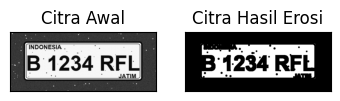

In [23]:
# Erosi Tanpa Library
def erosi_citra(F,k):
    # Size image
    m,n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k,k), dtype=np.uint8)
    constant = (k-1)//2

    imgE = np.zeros((m,n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m-constant):
        for j in range(constant, n-constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]
            product = temp*SE
            imgE[i,j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/PLAT_PCVK.jpeg', 0)

ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

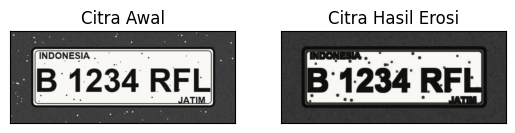

In [24]:
# EROSI LIBRARY
img = cv2.imread('/content/PLAT_PCVK.jpeg')

kernel = np.ones((5,5), np.uint8)

erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])

plt.show()

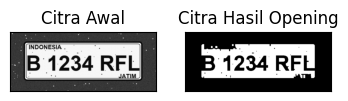

In [25]:
# Opening Tanpa Library Morphology

img_o = cv2.imread('/content/PLAT_PCVK.jpeg', 0)

reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

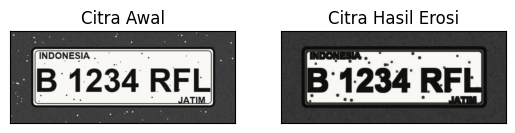

In [26]:
# EROSI LIBRARY
img = cv2.imread('/content/PLAT_PCVK.jpeg')

kernel = np.ones((5,5), np.uint8)

erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])

plt.show()

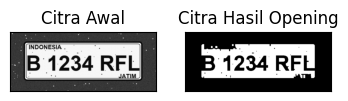

In [27]:
# Opening Tanpa Library Morphology

img_o = cv2.imread('/content/PLAT_PCVK.jpeg', 0)

reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

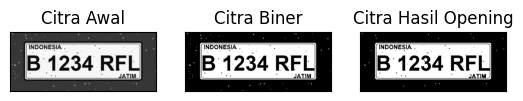

In [28]:
# Opening Menggunakan Library Morphology

img = cv2.imread('/content/PLAT_PCVK.jpeg', 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)

openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

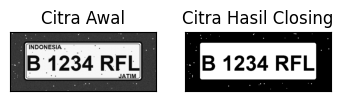

In [29]:
# Closing Tanpa Library Morphology

img_c = cv2.imread('/content/PLAT_PCVK.jpeg', 0)

retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

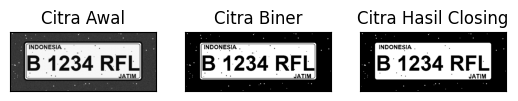

In [30]:
# Closing Menggunakan Library Morphology

img = cv2.imread('/content/PLAT_PCVK.jpeg', 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)

closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

SED = Cross 3


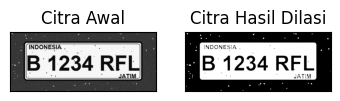

In [31]:
# Dilasi Cross SED 3x3

def dilasi_citra(F,w):
    # Size image
    p,q = F.shape

    imgD = np.zeros((p,q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)

    constant1 = (w-1)//2

    # Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]
            product = temp*SED
            imgD[i,j] = np.max(product)

    return imgD

print('SED = Cross 3')

img_d = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])

plt.show()

SED = Cross 5


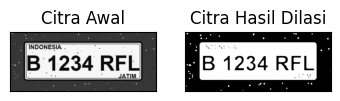

In [32]:
# Dilasi Cross SED 5x5

def dilasi_citra(F,w):
    # Size image
    p,q = F.shape

    imgD = np.zeros((p,q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)

    constant1 = (w-1)//2

    # Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]
            product = temp*SED
            imgD[i,j] = np.max(product)

    return imgD

print('SED = Cross 5')

img_d = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])

plt.show()

SED = Circle 3


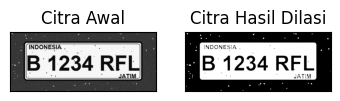

In [33]:
# Dilasi Circular SED

def dilasi_citra(F,w):
    # Size image
    p,q = F.shape

    imgD = np.zeros((p,q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
    constant1 = (w-1)//2

    # Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]
            product = temp*SED
            imgD[i,j] = np.max(product)

    return imgD

print('SED = Circle 3')

img_d = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])

plt.show()

SED = Circle 5


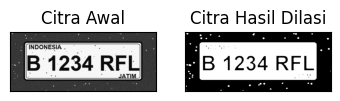

In [34]:
# Dilasi Circular 5x5

print('SED = Circle 5')

img_d = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])

plt.show()

SE = Rectangle 3x5


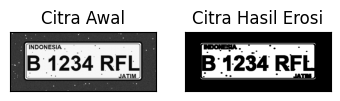

In [35]:
# Erosi Rectangle SE

def erosi_citra(F,p,l):
    # Size image
    m,n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l))
    constant1 = (l-1)//2
    constant2 = (p-1)//2

    imgE = np.zeros((m,n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m-constant1):
        for j in range(constant2, n-constant2):
            temp = F[i-constant1:i+constant1+1,
                     j-constant2:j+constant2+1]
            product = temp*SE
            imgE[i,j] = np.min(product)

    return imgE

print('SE = Rectangle 3x5')

img_e = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 5
l = 3
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])

plt.show()

SE = Rectangle 5x7


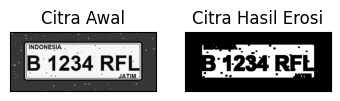

In [36]:
# Erosi Rectangle 5x7

print('SE = Rectangle 5x7')

img_e = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 7
l = 5
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])

plt.show()

SE = Line Vertikal 3


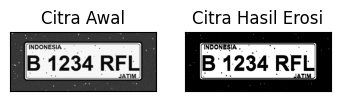

In [37]:
# Erosi Line Vertikal SE

def erosi_citra(F,k):
    # Size image
    m,n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k))
    constant = (k-1)//2

    imgE = np.zeros((m,n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m-constant):
        for j in range(n):
            temp = F[i-constant:i+constant+1, j:j+1]
            product = temp*SE
            imgE[i,j] = np.min(product)

    return imgE

print('SE = Line Vertikal 3')

img_e = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

k = 3
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])

plt.show()

SE = Line Vertikal 5


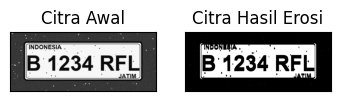

In [38]:
# Erosi Line Vertikal 5

print('SE = Line Vertikal 5')

img_e = cv2.imread('/content/PLAT_PCVK.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])

plt.subplot(132),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])

plt.show()

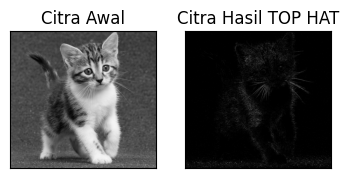

In [44]:
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img,
                              cv2.MORPH_TOPHAT,
                              kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])

plt.show()

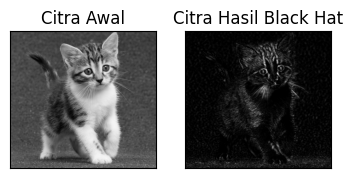

In [43]:
# BLACKHAT

filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])

plt.show()

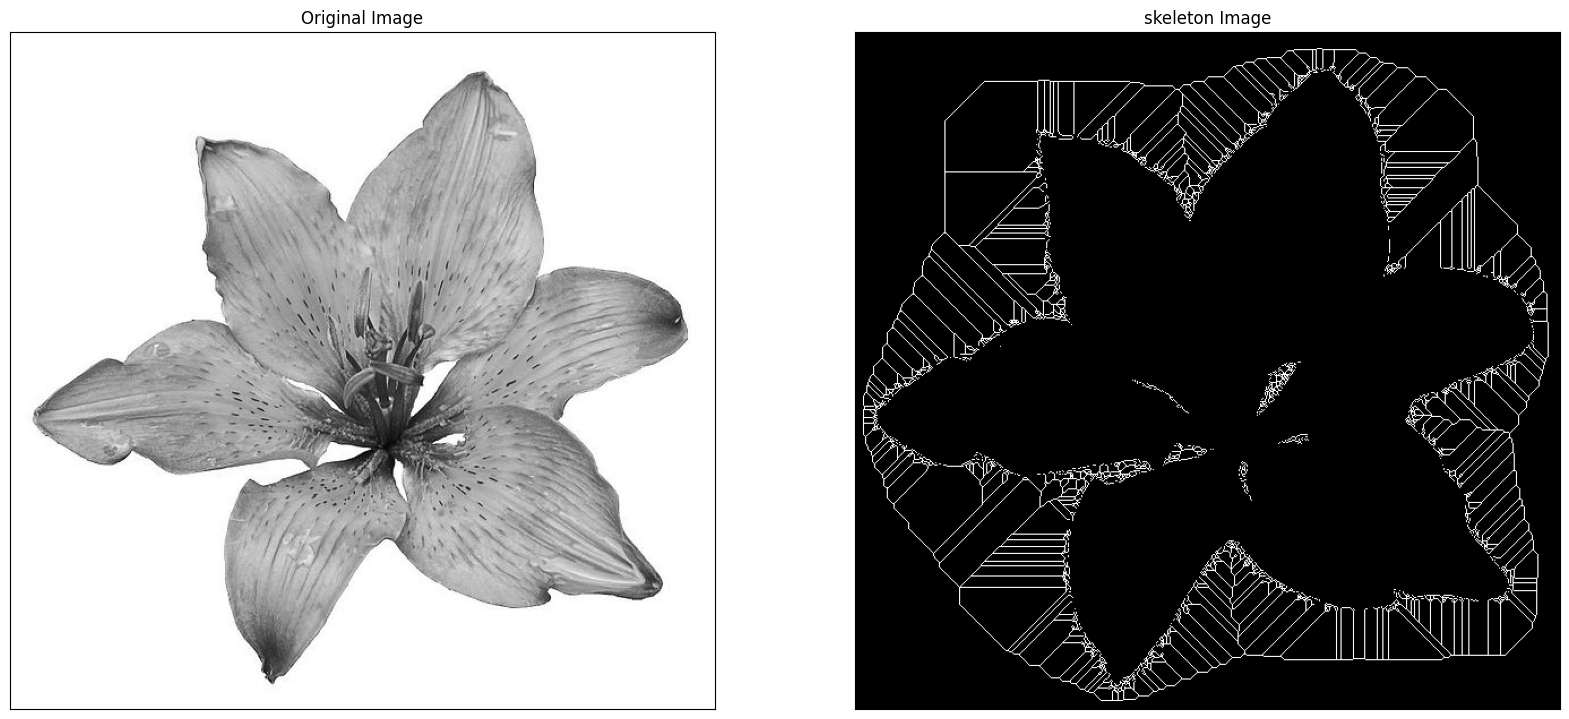

In [42]:
# Skeleton
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg', 0)

binary = img > filters.threshold_triangle(img)

# True false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# Skeletonize image
skeleton = skeletonize(binary_cp)

# Print images
plt.figure(figsize=(20,20))

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

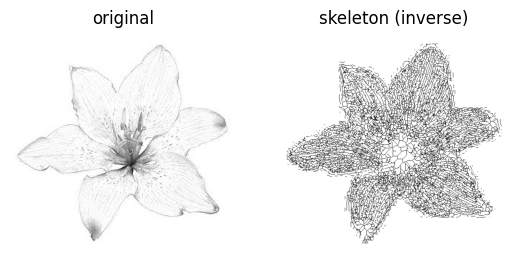

In [47]:
# Skeleton Inverse
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# Skeletonize image
skeleton = skeletonize(binary)

# Print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# Note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

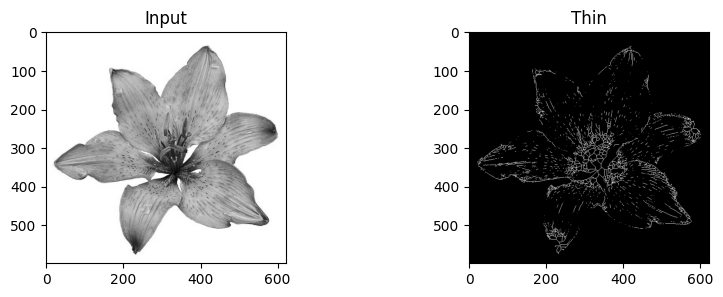

In [45]:
# Thickening
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

TUGAS

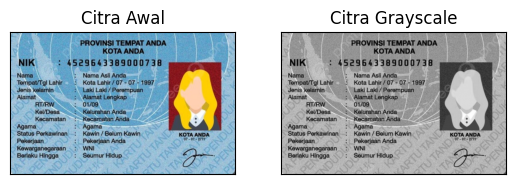

In [48]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize, thin

# Membaca citra KTP
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/ktp.jpg')

# Mengubah citra menjadi grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(gray, cmap='gray')
plt.title('Citra Grayscale'), plt.xticks([]), plt.yticks([])

plt.show()

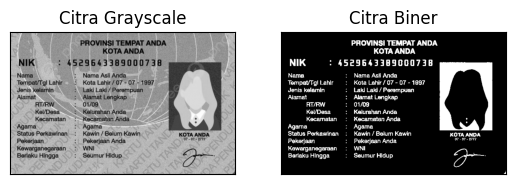

In [49]:
# Thresholding menggunakan metode Otsu
ret, thresh = cv2.threshold(gray, 0, 255,
                            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.subplot(121), plt.imshow(gray, cmap='gray')
plt.title('Citra Grayscale'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.show()

In [50]:
# Menentukan Structuring Element
kernel = np.ones((3,3), np.uint8)

# Operasi Erosi
erosi = cv2.erode(thresh, kernel, iterations=1)

# Operasi Dilasi
dilasi = cv2.dilate(thresh, kernel, iterations=1)

# Operasi Opening
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

# Operasi Closing
closing = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

# Operasi Top-Hat
tophat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, kernel)

# Operasi Black-Hat
kernel_blackhat = cv2.getStructuringElement(cv2.MORPH_RECT, (13,5))
blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel_blackhat)

# Operasi Skeleton
skeleton = skeletonize(thresh > 0)

# Operasi Thinning
thinning = thin(thresh > 0)

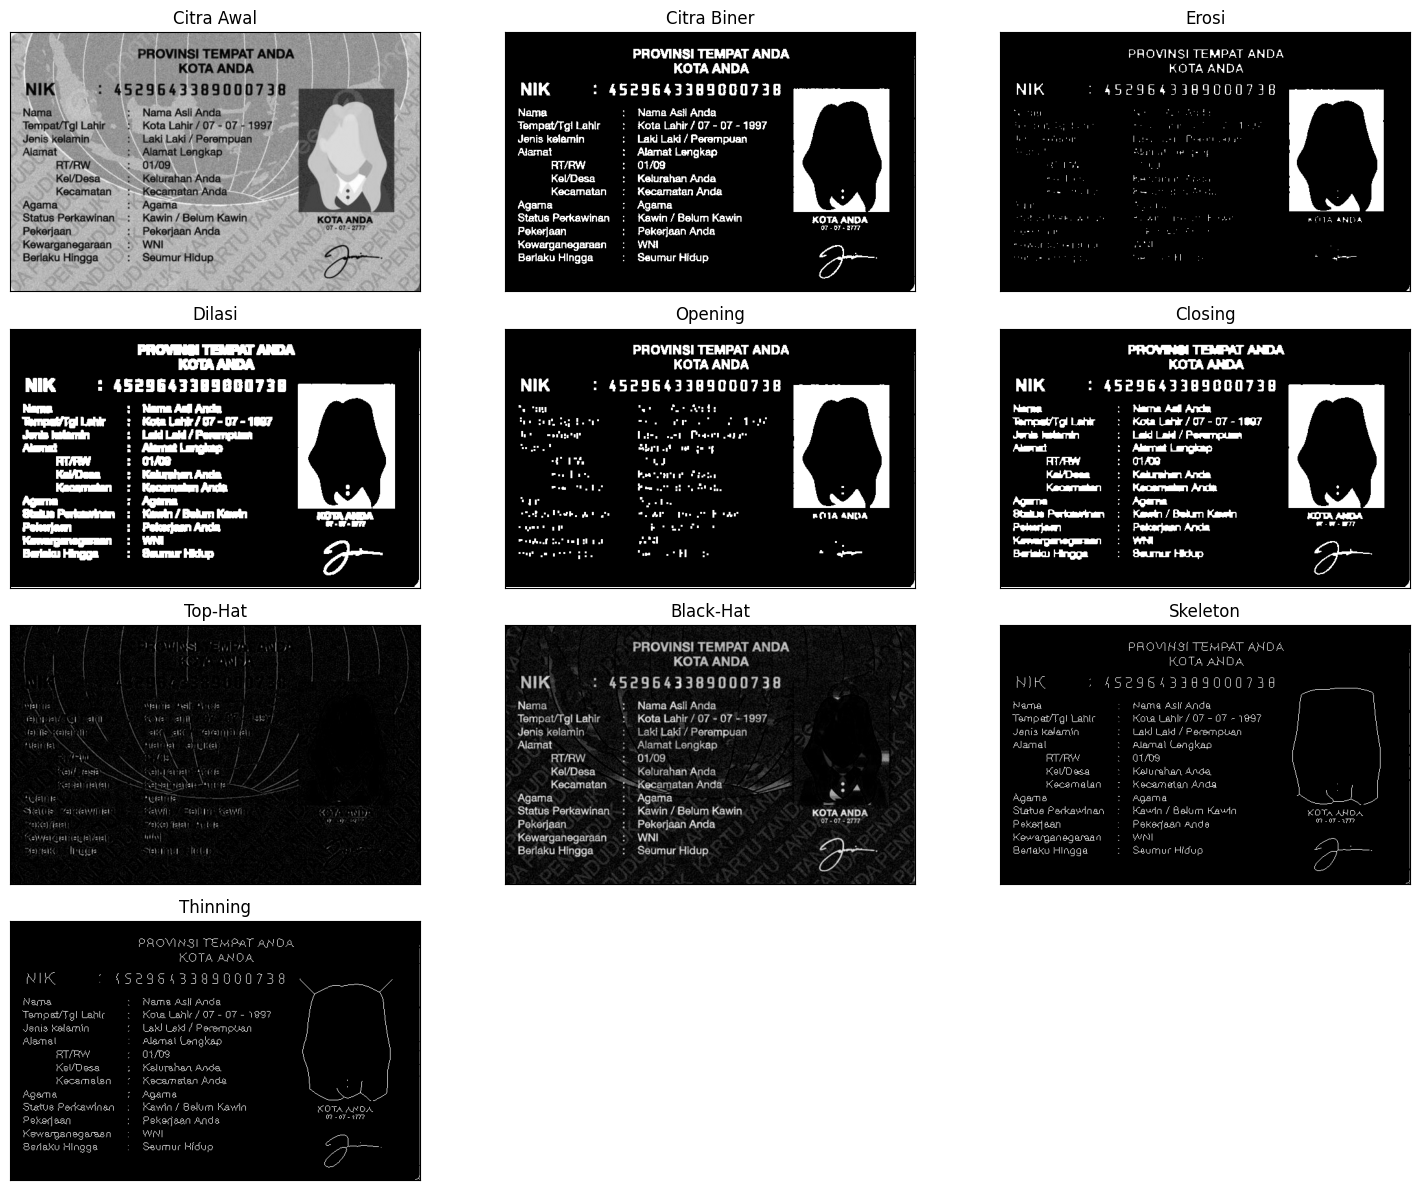

In [51]:
# Menampilkan hasil pengolahan citra KTP
judul = ['Citra Awal', 'Citra Biner', 'Erosi',
         'Dilasi', 'Opening', 'Closing',
         'Top-Hat', 'Black-Hat', 'Skeleton', 'Thinning']

gambar = [gray, thresh, erosi,
          dilasi, opening, closing,
          tophat, blackhat, skeleton, thinning]

plt.figure(figsize=(15, 12))

for i in range(len(gambar)):
    plt.subplot(4, 3, i+1)
    plt.imshow(gambar[i], cmap='gray')
    plt.title(judul[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Sesuai hasil pengujian terlihat bahwa setiap operasi memberikan hasil yang berbeda. Operasi erosi membuat sebagian tulisan menjadi lebih tipis dan menghilang, dilasi membuat tulisan menjadi lebih tebal. Opening, beberapa bagian tulisan ikut menghilang, closing menghasilkan tulisan yang relatif masih terlihat jelas. Hasil skeleton dan thinning memperlihatkan struktur tulisan yang semakin tipis. Dari pengujian ini, citra biner dan closing terlihat lebih mudah dibaca dibandingkan beberapa operasi lainnya.

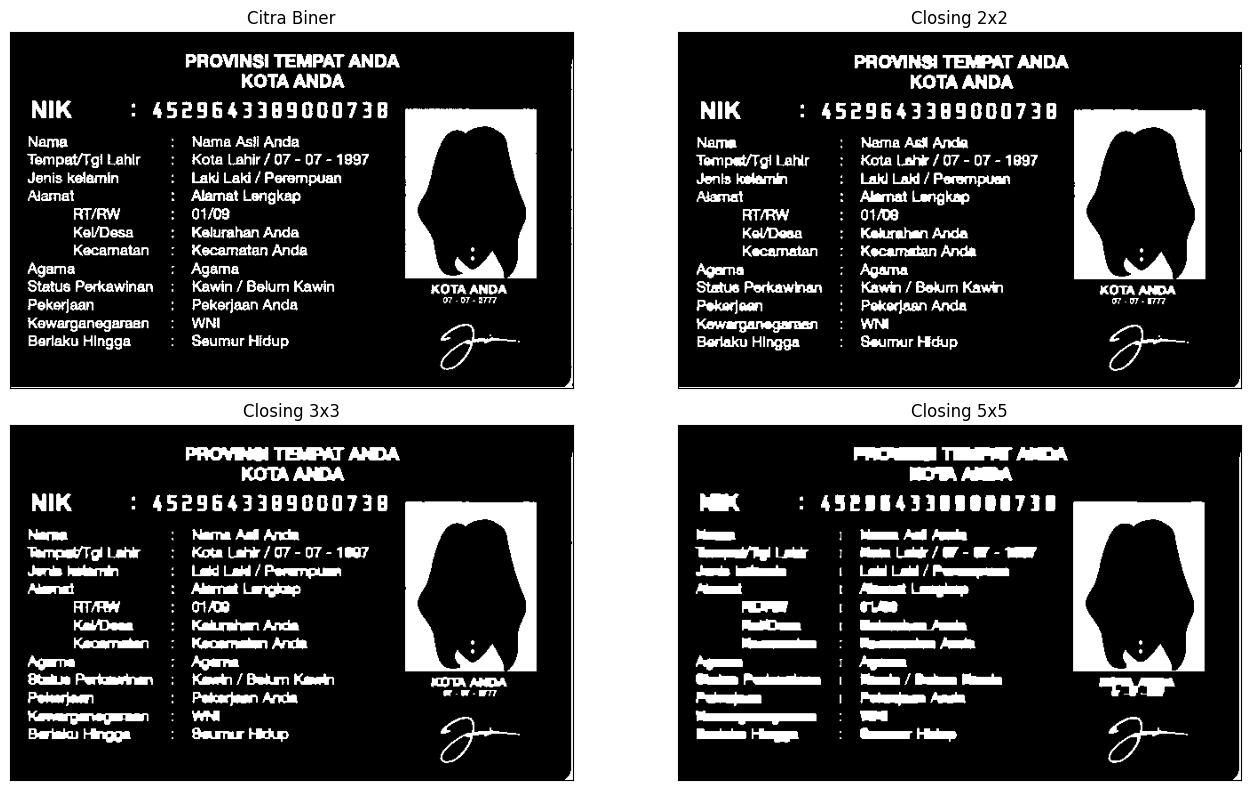

In [52]:
# Percobaan Closing dengan kernel berbeda
kernel2 = np.ones((2,2), np.uint8)
kernel3 = np.ones((3,3), np.uint8)
kernel5 = np.ones((5,5), np.uint8)

closing2 = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel2)
closing3 = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel3)
closing5 = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel5)

plt.figure(figsize=(14, 8))

plt.subplot(221), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(222), plt.imshow(closing2, cmap='gray')
plt.title('Closing 2x2'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(closing3, cmap='gray')
plt.title('Closing 3x3'), plt.xticks([]), plt.yticks([])

plt.subplot(224), plt.imshow(closing5, cmap='gray')
plt.title('Closing 5x5'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Sesuai hasil pengujian operasi closing dengan ukuran kernel 2x2, 3x3, dan 5x5 pada citra KTP, terlihat bahwa setiap ukuran kernel memberikan hasil yang berbeda. Pada kernel 2x2, tulisan masih terlihat jelas dan mudah dibaca. Sementara itu, kernel 3x3 membuat beberapa tulisan mulai menebal dan menyatu, sedangkan kernel 5x5 menyebabkan banyak tulisan menjadi terlalu tebal sehingga sulit dibaca. Dari hasil pengujian tersebut, kernel 2x2 memberikan hasil paling baik dibandingkan ukuran kernel lainnya karena bentuk tulisan masih dapat dipertahankan.